In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=ac1f52f1-88e7-4fd1-b580-38e64f40790e
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:06<00:00, 123MB/s]  

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    clean_list.csv
    noise_manifest_v2.json
    b6000_split.csv
    noisy_metadata_v2.csv
    noisy_500_v2/
        U/
            00002357_U_500_roll_01.png
            00002483_U_500_roll_06.png
            00002399_U_500_roll_07.png
            00002508_U_500_roll_04.png
            00002614_U_500_roll_08.png
            00002375_U_500_roll_01.png
            00002626_U_500_roll_07.png
            00002401_U_500_roll_01.png
            00002352_U_500_roll_03.png
            00002348_U_500_roll_06.png
            00002420_U_500_roll_03.png
            00002630_U_500_roll_03.png
            00002418_U_500_roll_07.png
            00002448_U_500_roll_09.png
            00002367_U_500_roll_06.png
            00002454_U_500_roll_01.png
            00002544_U_500_roll_01.png
            00002516_U_500_roll_04.png
            00002348_U_500_roll_05.png
            00002641_U_500_roll_06.png
        S/
            00002518_S_500_slap_02.png
            00002510_S_500_slap

In [4]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
clean_list.csv
noise_manifest_v2.json
b6000_split.csv
noisy_metadata_v2.csv
clean_500/U/00002357_U_500_roll_01.png
clean_500/U/00002483_U_500_roll_06.png
clean_500/U/00002399_U_500_roll_07.png
clean_500/U/00002508_U_500_roll_04.png
clean_500/U/00002614_U_500_roll_08.png
clean_500/U/00002375_U_500_roll_01.png
clean_500/U/00002626_U_500_roll_07.png
clean_500/U/00002401_U_500_roll_01.png
clean_500/U/00002352_U_500_roll_03.png
clean_500/U/00002348_U_500_roll_06.png
clean_500/U/00002420_U_500_roll_03.png
clean_500/U/00002630_U_500_roll_03.png
clean_500/U/00002418_U_500_roll_07.png
clean_500/U/00002448_U_500_roll_09.png
clean_500/U/00002367_U_500_roll_06.png
clean_500/U/00002454_U_500_roll_01.png
clean_500/U/00002544_U_500_roll_01.png
clean_500/U/00002516_U_500_roll_04.png
clean_500/U/00002348_U_500_roll_05.png
clean_500/U/00002641_U_500_roll_06.png
clean_500/U/00002338_U_500_roll_01.png
clean

In [5]:
import torch
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
!nvidia-smi
!pip -q list 2>/dev/null | grep -i -E "scikit-image|opencv|pandas|nbis"

torch: 2.11.0+cu128 | CUDA: True
Thu Oct 29 06:31:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------

In [6]:
import pandas as pd
root = "/kaggle/working/dataset/noise_project_v2"

for f in ["b6000_split.csv", "clean_list.csv", "noisy_metadata_v2.csv"]:
    df = pd.read_csv(f"{root}/{f}")
    print("\n====", f, df.shape)
    print(df.columns.tolist())
    display(df.head(3))

split = pd.read_csv(f"{root}/b6000_split.csv")
for c in split.columns:
    if split[c].nunique() < 15:
        print("\n", c, split[c].value_counts().to_dict())


==== b6000_split.csv (6000, 30)
['source', 'key', 'participant', 'device', 'ppi', 'capture', 'frgp', 'finger_name', 'zip_member', 'sha256', 'has_g_minutiae', 'sibling_1000_annotated', 'n_minutiae', 'g_irr_path', 'minutiae_mode', 'group_id', 'g_key', 'items_9_331_minutiae', 'items_9_320', 'items_9_321', 'items_9_325', 'items_9_326', 'has_class_9_307', 'class_9_307', 'has_annotation', 'nfiq2', 'valid', 'nfiq2_bin', 'quality_group', 'split']


,source,key,participant,device,ppi,capture,frgp,finger_name,zip_member,sha256,...,items_9_325,items_9_326,has_class_9_307,class_9_307,has_annotation,nfiq2,valid,nfiq2_bin,quality_group,split
0,b,00002302_R_500_slap_01,2302,R,500,slap-segmented,1,R thumb,sd302b/images/baseline/R/500/slap-segmented/pn...,c5ee6ca25aa48b27c25a70bc28c0f15bf99fa55c333fcb...,...,NaN,NaN,NaN,NaN,False,81,True,81-100,clean,train
1,b,00002302_R_500_slap_02,2302,R,500,slap-segmented,2,R index,sd302b/images/baseline/R/500/slap-segmented/pn...,84d65767e492d22536405376447a883db476482c4ab664...,...,NaN,NaN,NaN,NaN,False,55,True,41-60,middle,train
2,b,00002302_R_500_slap_03,2302,R,500,slap-segmented,3,R middle,sd302b/images/baseline/R/500/slap-segmented/pn...,ce0304e9e35ba73fdd96d16c441e5532175189d4b3a503...,...,NaN,NaN,NaN,NaN,False,73,True,61-80,clean,train



==== clean_list.csv (2490, 31)
['source', 'key', 'participant', 'device', 'ppi', 'capture', 'frgp', 'finger_name', 'zip_member', 'sha256', 'has_g_minutiae', 'sibling_1000_annotated', 'n_minutiae', 'g_irr_path', 'minutiae_mode', 'group_id', 'g_key', 'items_9_331_minutiae', 'items_9_320', 'items_9_321', 'items_9_325', 'items_9_326', 'has_class_9_307', 'class_9_307', 'has_annotation', 'nfiq2', 'valid', 'nfiq2_bin', 'quality_group', 'split', 'clean_path']


,source,key,participant,device,ppi,capture,frgp,finger_name,zip_member,sha256,...,items_9_326,has_class_9_307,class_9_307,has_annotation,nfiq2,valid,nfiq2_bin,quality_group,split,clean_path
0,b,00002302_R_500_slap_01,2302,R,500,slap-segmented,1,R thumb,sd302b/images/baseline/R/500/slap-segmented/pn...,c5ee6ca25aa48b27c25a70bc28c0f15bf99fa55c333fcb...,...,NaN,NaN,NaN,False,81,True,81-100,clean,train,/content/drive/MyDrive/NIST/noise_project/clea...
1,b,00002302_R_500_slap_03,2302,R,500,slap-segmented,3,R middle,sd302b/images/baseline/R/500/slap-segmented/pn...,ce0304e9e35ba73fdd96d16c441e5532175189d4b3a503...,...,NaN,NaN,NaN,False,73,True,61-80,clean,train,/content/drive/MyDrive/NIST/noise_project/clea...
2,b,00002302_R_500_slap_06,2302,R,500,slap-segmented,6,L thumb,sd302b/images/baseline/R/500/slap-segmented/pn...,268e7ab2924ddbbf4bcc964b946443a68103ab97934b99...,...,NaN,NaN,NaN,False,78,True,61-80,clean,train,/content/drive/MyDrive/NIST/noise_project/clea...



==== noisy_metadata_v2.csv (2490, 17)
['key', 'device', 'split', 'participant', 'frgp', 'has_annotation', 'clean_nfiq2', 'noisy_nfiq2', 'attempts', 'seed_used', 'cfg_used', 'noises', 'overink_strength', 'target', 'kept_above30', 'clean_path', 'noisy_path']


,key,device,split,participant,frgp,has_annotation,clean_nfiq2,noisy_nfiq2,attempts,seed_used,cfg_used,noises,overink_strength,target,kept_above30,clean_path,noisy_path
0,00002546_V_500_roll_05,V,train,2546,5,True,77,25,1,2026,Q2,creases+overink+scratch,1.863,55,False,/content/drive/MyDrive/NIST/noise_project/clea...,/content/drive/MyDrive/NIST/noise_project/nois...
1,00002449_U_500_roll_02,U,train,2449,2,False,67,11,3,4026,Q2,creases+fragment+overink+smudge+gauss,2.016,10,True,/content/drive/MyDrive/NIST/noise_project/clea...,/content/drive/MyDrive/NIST/noise_project/nois...
2,00002624_S_500_slap_04,S,val,2624,4,False,87,3,4,5026,STRONG,overink+creases+partial+blur,3.192,55,False,/content/drive/MyDrive/NIST/noise_project/clea...,/content/drive/MyDrive/NIST/noise_project/nois...



 source {'b': 6000}

 device {'V': 2000, 'U': 2000, 'S': 1080, 'R': 920}

 ppi {500: 6000}

 capture {'roll': 4000, 'slap-segmented': 2000}

 frgp {1: 600, 2: 600, 3: 600, 4: 600, 5: 600, 6: 600, 7: 600, 8: 600, 9: 600, 10: 600}

 finger_name {'R thumb': 600, 'R index': 600, 'R middle': 600, 'R ring': 600, 'R little': 600, 'L thumb': 600, 'L index': 600, 'L middle': 600, 'L ring': 600, 'L little': 600}

 has_g_minutiae {False: 5973, True: 27}

 sibling_1000_annotated {False: 3833, True: 2167}

 minutiae_mode {'none': 3806, 'scaled_from_1000': 2167, 'exact_500': 27}

 items_9_320 {1.0: 1704, 2.0: 355, 0.0: 132, 3.0: 3}

 items_9_321 {1.0: 1430, 2.0: 592, 0.0: 169, 3.0: 3}

 items_9_325 {0.0: 2062, 1.0: 132}

 items_9_326 {0.0: 2025, 1.0: 169}

 has_class_9_307 {True: 2194}

 class_9_307 {'RS': 698, 'WU': 655, 'LS': 651, 'AU': 178, 'UC': 12}

 has_annotation {False: 3806, True: 2194}

 valid {True: 6000}

 nfiq2_bin {'61-80': 1904, '41-60': 1839, '21-40': 1030, '0-20': 740, '81-100': 48

In [7]:
from pathlib import Path
import cv2

clean_dir = Path(root) / "clean_500"
noisy_dir = Path(root) / "noisy_500_v2"

clean = sorted(p.relative_to(clean_dir) for p in clean_dir.rglob("*.png"))
noisy = sorted(p.relative_to(noisy_dir) for p in noisy_dir.rglob("*.png"))
print("clean:", len(clean), "| noisy:", len(noisy), "| matching names:", len(set(clean) & set(noisy)))

# sample image sizes
import random
for p in random.sample(clean, 6):
    c = cv2.imread(str(clean_dir / p), cv2.IMREAD_UNCHANGED)
    n = cv2.imread(str(noisy_dir / p), cv2.IMREAD_UNCHANGED)
    print(p, "| clean", c.shape, c.dtype, c.min(), c.max(), "| noisy", n.shape, n.dtype)

clean: 2490 | noisy: 2490 | matching names: 2490
R/00002412_R_500_slap_03.png | clean (458, 309) uint8 0 255 | noisy (458, 309) uint8
S/00002505_S_500_slap_04.png | clean (451, 310) uint8 0 255 | noisy (451, 310) uint8
U/00002538_U_500_roll_10.png | clean (750, 800) uint8 0 255 | noisy (750, 800) uint8
V/00002330_V_500_roll_03.png | clean (750, 800) uint8 1 255 | noisy (750, 800) uint8
V/00002367_V_500_roll_05.png | clean (750, 800) uint8 0 255 | noisy (750, 800) uint8
R/00002428_R_500_slap_04.png | clean (484, 289) uint8 7 255 | noisy (484, 289) uint8


In [17]:
import os, time, random, json
import numpy as np, pandas as pd, cv2, torch
import torch.nn as nn, torch.nn.functional as F
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import structural_similarity as ssim_fn, peak_signal_noise_ratio as psnr_fn
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/working/dataset/noise_project_v2")
CLEAN_DIR = ROOT / "clean_500"
NOISY_DIR = ROOT / "noisy_500_v2"
OUT = Path("/kaggle/working/fingernet_out")
(OUT / "enhanced").mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda"

CROP = 256          # training crop size
BATCH = 16
CROPS_PER_IMG = 4   # crops per image per epoch
LR = 2e-4
EPOCHS_S1 = 60     # stage 1: enhancement only
EPOCHS_S2 = 30      # stage 2: multi-task fine-tune
N_CLASSES = 20      # orientation classes (9 deg each)
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 Tesla T4


In [18]:
meta = pd.read_csv(ROOT / "noisy_metadata_v2.csv")
meta["rel"] = meta["device"] + "/" + meta["key"] + ".png"
print(meta["split"].value_counts())

train_df = meta[meta.split == "train"].reset_index(drop=True)
val_df   = meta[meta.split == "val"].reset_index(drop=True)
test_df  = meta[meta.split == "test"].reset_index(drop=True)
print("train", len(train_df), "| val", len(val_df), "| test", len(test_df))
assert (CLEAN_DIR / train_df.rel[0]).exists() and (NOISY_DIR / train_df.rel[0]).exists()

split
train    1764
val       388
test      338
Name: count, dtype: int64
train 1764 | val 388 | test 338


In [19]:
def read_gray(p):
    return cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)

def orientation_labels(img01, sigma=6, coh_thr=0.35):
    """Gradient-based ridge orientation -> 20 classes. Background = -100 (ignored)."""
    gx = cv2.Sobel(img01, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img01, cv2.CV_32F, 0, 1, ksize=3)
    gxx = cv2.GaussianBlur(gx * gx, (0, 0), sigma)
    gyy = cv2.GaussianBlur(gy * gy, (0, 0), sigma)
    gxy = cv2.GaussianBlur(gx * gy, (0, 0), sigma)
    theta = np.mod(0.5 * np.arctan2(2 * gxy, gxx - gyy) + np.pi / 2, np.pi)
    lab = np.minimum((theta / (np.pi / N_CLASSES)).astype(np.int64), N_CLASSES - 1)
    coh = np.sqrt((gxx - gyy) ** 2 + 4 * gxy ** 2) / (gxx + gyy + 1e-8)
    lab[(coh < coh_thr) | ((gxx + gyy) < 1e-3)] = -100
    return lab

class FPTrain(Dataset):
    def __init__(self, df):
        self.rel = df.rel.tolist()
    def __len__(self):
        return len(self.rel) * CROPS_PER_IMG
    def __getitem__(self, i):
        r = self.rel[i % len(self.rel)]
        n = read_gray(NOISY_DIR / r); c = read_gray(CLEAN_DIR / r)
        h, w = c.shape
        ph, pw = max(0, CROP - h), max(0, CROP - w)
        if ph or pw:
            n = cv2.copyMakeBorder(n, 0, ph, 0, pw, cv2.BORDER_REPLICATE)
            c = cv2.copyMakeBorder(c, 0, ph, 0, pw, cv2.BORDER_REPLICATE)
            h, w = c.shape
        y = random.randint(0, h - CROP); x = random.randint(0, w - CROP)
        n = n[y:y + CROP, x:x + CROP]; c = c[y:y + CROP, x:x + CROP]
        if random.random() < 0.5:
            n, c = n[:, ::-1], c[:, ::-1]
        n = np.ascontiguousarray(n).astype(np.float32) / 255
        c = np.ascontiguousarray(c).astype(np.float32) / 255
        lab = orientation_labels(c)
        return (torch.from_numpy(n)[None], torch.from_numpy(c)[None], torch.from_numpy(lab))

train_loader = DataLoader(FPTrain(train_df), batch_size=BATCH, shuffle=True,
                          num_workers=4, drop_last=True, pin_memory=True)
xb, yb, lb = next(iter(train_loader))
print(xb.shape, yb.shape, lb.shape, "ignored frac:", (lb == -100).float().mean().item())

torch.Size([16, 1, 256, 256]) torch.Size([16, 1, 256, 256]) torch.Size([16, 256, 256]) ignored frac: 0.4093446731567383


In [20]:
class FingerNet(nn.Module):
    def __init__(self, c=64, n_cls=N_CLASSES):
        super().__init__()
        # encoder (shared)
        self.conv1 = nn.Conv2d(1, c, 9, stride=4, padding=4)
        self.conv2 = nn.Conv2d(c, c, 5, padding=2)
        self.conv3 = nn.Conv2d(c, c, 3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2, return_indices=True)
        self.conv4 = nn.Conv2d(c, c, 3, padding=1)
        self.unpool = nn.MaxUnpool2d(2, 2)
        # enhancement decoder (with skips)
        self.e_d4 = nn.ConvTranspose2d(c, c, 3, padding=1)
        self.e_d3 = nn.ConvTranspose2d(c, c, 3, padding=1)
        self.e_d2 = nn.ConvTranspose2d(c, c, 5, padding=2)
        self.e_d1 = nn.ConvTranspose2d(c, 1, 9, stride=4, padding=4, output_padding=3)
        # orientation decoder (no skips)
        self.o_d4 = nn.ConvTranspose2d(c, c, 3, padding=1)
        self.o_d3 = nn.ConvTranspose2d(c, c, 3, padding=1)
        self.o_d2 = nn.ConvTranspose2d(c, c, 5, padding=2)
        self.o_d1 = nn.ConvTranspose2d(c, n_cls, 9, stride=4, padding=4, output_padding=3)

    def forward(self, x, multitask=False):
        e1 = F.relu(self.conv1(x))
        e2 = F.relu(self.conv2(e1))
        e3 = F.relu(self.conv3(e2))
        p, idx = self.pool(e3)
        e4 = F.relu(self.conv4(p))
        # enhancement branch
        d = F.relu(self.e_d4(e4))
        d = self.unpool(d, idx, output_size=e3.shape) + e3
        d = F.relu(self.e_d3(d)) + e2
        d = F.relu(self.e_d2(d)) + e1
        enh = self.e_d1(d)
        ori = None
        if multitask:
            o = F.relu(self.o_d4(e4))
            o = self.unpool(o, idx, output_size=e3.shape)
            o = F.relu(self.o_d3(o))
            o = F.relu(self.o_d2(o))
            ori = self.o_d1(o)
        return enh, ori

model = FingerNet().to(DEVICE)
print("params (M):", sum(p.numel() for p in model.parameters()) / 1e6)
with torch.no_grad():
    a, b = model(torch.randn(2, 1, 256, 256, device=DEVICE), multitask=True)
print(a.shape, b.shape)   # expect [2,1,256,256] and [2,20,256,256]

params (M): 0.643093
torch.Size([2, 1, 256, 256]) torch.Size([2, 20, 256, 256])


In [23]:
@torch.no_grad()
def enhance(model, img_u8):
    h, w = img_u8.shape
    ph, pw = (8 - h % 8) % 8, (8 - w % 8) % 8
    x = torch.from_numpy(img_u8.astype(np.float32) / 255)[None, None].to(DEVICE)
    x = F.pad(x, (0, pw, 0, ph), mode="replicate")
    with torch.autocast("cuda", dtype=torch.float16):
        y, _ = model(x)
    y = y[0, 0, :h, :w].float().clamp(0, 1).cpu().numpy()
    return (y * 255).round().astype(np.uint8)

def eval_val(model, df, n=None):
    model.eval()
    rels = df.rel.tolist()[:n] if n else df.rel.tolist()
    ps, ss = [], []
    for r in rels:
        n_ = read_gray(NOISY_DIR / r); c_ = read_gray(CLEAN_DIR / r)
        e_ = enhance(model, n_)
        ps.append(psnr_fn(c_, e_, data_range=255))
        ss.append(ssim_fn(c_, e_, data_range=255))
    return float(np.mean(ps)), float(np.mean(ss))

def run_stage(name, epochs, multitask, init_ckpt=None):
    global model
    model = FingerNet().to(DEVICE)
    if init_ckpt:
        model.load_state_dict(torch.load(init_ckpt))
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda")
    best = -1; hist = []
    for ep in range(1, epochs + 1):
        model.train(); tot = 0; t0 = time.time()
        for xb, yb, lb in train_loader:
            xb, yb, lb = xb.to(DEVICE), yb.to(DEVICE), lb.to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16):
                enh, ori = model(xb, multitask=multitask)
            loss = F.mse_loss(enh.float(), yb)
            if multitask and (lb != -100).any():
                loss = loss + F.cross_entropy(ori.float(), lb, ignore_index=-100)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            tot += loss.item()
        sched.step()
        vp, vs = eval_val(model, val_df)
        hist.append((ep, tot / len(train_loader), vp, vs))
        print(f"[{name}] ep {ep:02d}/{epochs} loss {tot/len(train_loader):.4f} | "
              f"val PSNR {vp:.2f} SSIM {vs:.4f} | {time.time()-t0:.0f}s")
        torch.save(model.state_dict(), OUT / f"{name}_last.pt")
        if vp > best:
            best = vp; torch.save(model.state_dict(), OUT / f"{name}_best.pt")
    pd.DataFrame(hist, columns=["epoch", "loss", "val_psnr", "val_ssim"]).to_csv(OUT / f"{name}_hist.csv", index=False)
    print("best val PSNR:", best)

In [24]:
run_stage("stage1", EPOCHS_S1, multitask=False)

[stage1] ep 01/60 loss 0.0759 | val PSNR 14.05 SSIM 0.5707 | 65s
[stage1] ep 02/60 loss 0.0488 | val PSNR 14.82 SSIM 0.6303 | 64s
[stage1] ep 03/60 loss 0.0453 | val PSNR 15.29 SSIM 0.6645 | 64s
[stage1] ep 04/60 loss 0.0435 | val PSNR 15.50 SSIM 0.7440 | 65s
[stage1] ep 05/60 loss 0.0428 | val PSNR 15.36 SSIM 0.6693 | 64s
[stage1] ep 06/60 loss 0.0415 | val PSNR 15.60 SSIM 0.6850 | 64s
[stage1] ep 07/60 loss 0.0405 | val PSNR 15.68 SSIM 0.6931 | 64s
[stage1] ep 08/60 loss 0.0392 | val PSNR 15.63 SSIM 0.7180 | 64s
[stage1] ep 09/60 loss 0.0384 | val PSNR 15.93 SSIM 0.7374 | 64s
[stage1] ep 10/60 loss 0.0379 | val PSNR 15.35 SSIM 0.6569 | 63s
[stage1] ep 11/60 loss 0.0370 | val PSNR 16.18 SSIM 0.7412 | 63s
[stage1] ep 12/60 loss 0.0360 | val PSNR 15.90 SSIM 0.6991 | 63s
[stage1] ep 13/60 loss 0.0359 | val PSNR 16.37 SSIM 0.7938 | 63s
[stage1] ep 14/60 loss 0.0348 | val PSNR 16.09 SSIM 0.7481 | 62s
[stage1] ep 15/60 loss 0.0348 | val PSNR 15.84 SSIM 0.7451 | 63s
[stage1] ep 16/60 loss 0.

In [25]:
!pip -q install nbis-python
import nbis, cv2

_settings = nbis.NbisExtractorSettings(
    min_quality=0.0, get_center=False, check_fingerprint=False,
    compute_nfiq2=True, ppi=500.0)
_extractor = nbis.new_nbis_extractor(_settings)   
_err_shown = False

def nfiq2_score(img_u8):
    """img_u8: 2D uint8 numpy array (500 ppi). Returns NFIQ2 score (0-100)."""
    global _err_shown
    try:
        ok, buf = cv2.imencode(".png", img_u8)
        return float(_extractor.extract_minutiae(buf.tobytes()).quality().score)
    except Exception as e:
        if not _err_shown:
            print("NFIQ2 error:", repr(e)); _err_shown = True
        return float("nan")

# sanity check: dataset ke apne nfiq2 column se compare
ref = pd.read_csv(ROOT / "clean_list.csv").set_index("key")["nfiq2"]
tmap = test_df.set_index("key")["rel"]
for k in test_df.key[:5]:
    img = read_gray(CLEAN_DIR / tmap[k])
    print(k, "| mine:", nfiq2_score(img), "| csv:", ref.get(k))

00002434_U_500_roll_01 | mine: 81.0 | csv: 81
00002303_R_500_slap_02 | mine: 74.0 | csv: 74
00002303_R_500_slap_06 | mine: 65.0 | csv: 65
00002303_R_500_slap_07 | mine: 66.0 | csv: 66
00002325_R_500_slap_01 | mine: 66.0 | csv: 66


In [29]:
res = pd.read_csv(OUT / "test_results.csv")
tmap = test_df.set_index("key")["rel"]

n_noisy, n_enh, n_clean = [], [], []
for k in tqdm(res.key):
    rel = tmap[k]
    n_noisy.append(nfiq2_score(read_gray(NOISY_DIR / rel)))
    n_enh.append(nfiq2_score(read_gray(OUT / "enhanced" / rel)))
    n_clean.append(nfiq2_score(read_gray(CLEAN_DIR / rel)))

res["nfiq2_noisy"], res["nfiq2_enh"], res["nfiq2_clean"] = n_noisy, n_enh, n_clean
res.to_csv(OUT / "test_results.csv", index=False)
print("NaN count:", res[["nfiq2_noisy", "nfiq2_enh", "nfiq2_clean"]].isna().sum().to_dict())

  0%|          | 0/338 [00:00<?, ?it/s]

NaN count: {'nfiq2_noisy': 0, 'nfiq2_enh': 0, 'nfiq2_clean': 0}


In [30]:
summ = pd.DataFrame({
    "Before (noisy)": [res.ssim_noisy.mean(), res.psnr_noisy.mean(), res.rmse_noisy.mean(), res.nfiq2_noisy.mean()],
    "After (FingerNet)": [res.ssim_enh.mean(), res.psnr_enh.mean(), res.rmse_enh.mean(), res.nfiq2_enh.mean()],
}, index=["SSIM", "PSNR (dB)", "RMSE", "NFIQ2"]).round(3)
print(summ)
print("NFIQ2 clean reference:", round(res.nfiq2_clean.mean(), 2))
print("Improved NFIQ2:", (res.nfiq2_enh > res.nfiq2_noisy).sum(), "/", len(res))
print("Improved SSIM :", (res.ssim_enh > res.ssim_noisy).sum(), "/", len(res))
print("Avg time/image: %.3f s" % res.time_s.mean())

print(res.groupby("device")[["ssim_noisy", "ssim_enh", "psnr_noisy", "psnr_enh",
                             "nfiq2_noisy", "nfiq2_enh"]].mean().round(3))

           Before (noisy)  After (FingerNet)
SSIM                0.672              0.803
PSNR (dB)          13.288             17.229
RMSE               57.600             36.295
NFIQ2              20.083             70.361
NFIQ2 clean reference: 71.77
Improved NFIQ2: 338 / 338
Improved SSIM : 326 / 338
Avg time/image: 0.012 s
        ssim_noisy  ssim_enh  psnr_noisy  psnr_enh  nfiq2_noisy  nfiq2_enh
device                                                                    
R            0.558     0.719      11.091    15.136       16.350     73.750
S            0.586     0.756      11.906    15.891       20.247     73.280
U            0.766     0.856      14.728    18.513       18.885     66.462
V            0.732     0.852      14.652    18.667       24.198     69.506


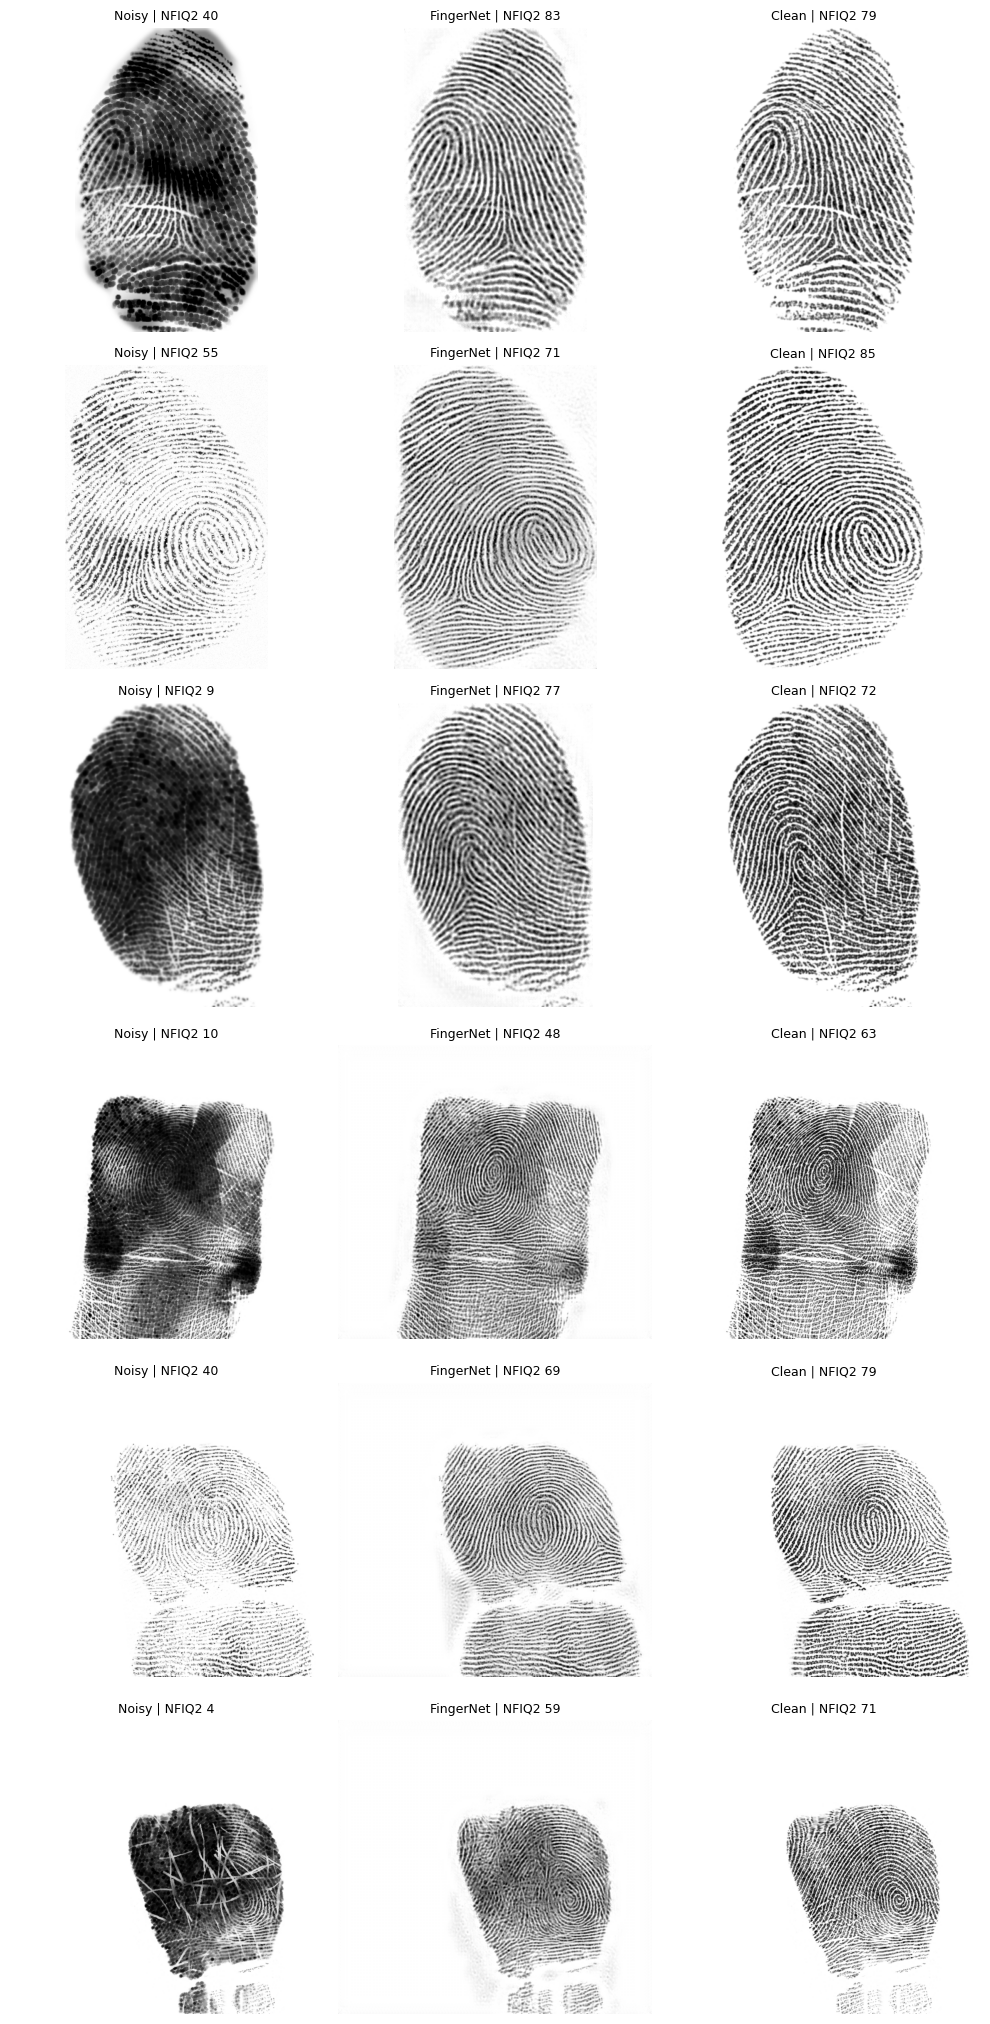

In [31]:
samples = res.sample(6, random_state=1)
fig, axs = plt.subplots(len(samples), 3, figsize=(10, 3.4 * len(samples)))
for i, (_, r) in enumerate(samples.iterrows()):
    rel = f"{r.device}/{r.key}.png"
    imgs = [read_gray(NOISY_DIR / rel), read_gray(OUT / "enhanced" / rel), read_gray(CLEAN_DIR / rel)]
    titles = [f"Noisy | NFIQ2 {r.nfiq2_noisy:.0f}", f"FingerNet | NFIQ2 {r.nfiq2_enh:.0f}", f"Clean | NFIQ2 {r.nfiq2_clean:.0f}"]
    for j in range(3):
        axs[i, j].imshow(imgs[j], cmap="gray"); axs[i, j].set_title(titles[j], fontsize=9); axs[i, j].axis("off")
plt.tight_layout(); plt.savefig(OUT / "visual_comparison.png", dpi=150); plt.show()

In [32]:
res = pd.read_csv(OUT / "test_results.csv")
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.3})
C_NOISY, C_ENH, C_CLEAN = "#d95f02", "#1b9e77", "#7570b3"

def save(name):
    plt.tight_layout(); plt.savefig(OUT / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()

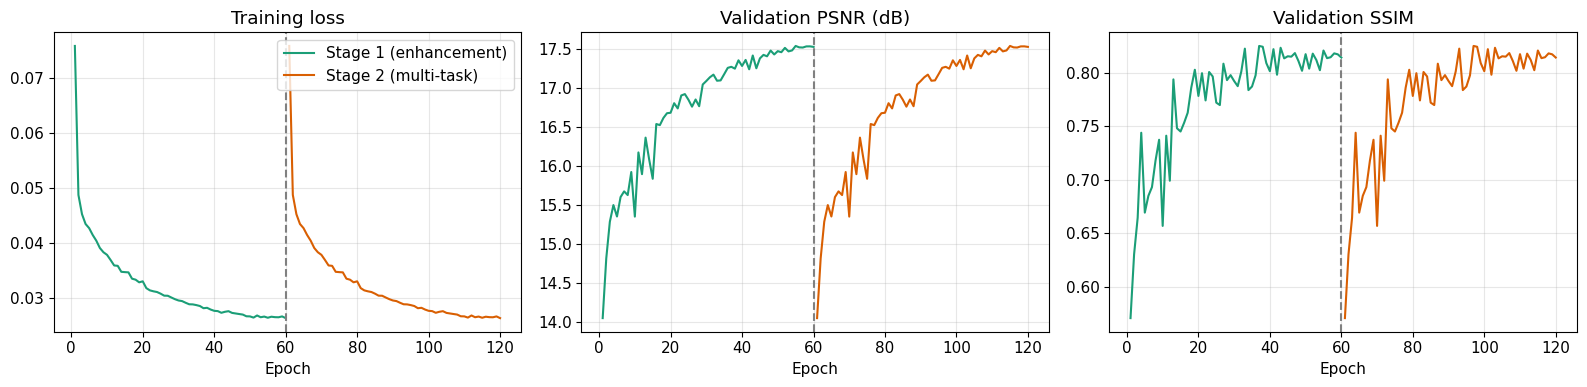

In [34]:
h1 = pd.read_csv(OUT / "stage1_hist.csv"); h2 = pd.read_csv(OUT / "stage1_hist.csv")
h2["epoch_g"] = h2.epoch + len(h1); h1["epoch_g"] = h1.epoch

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, t in zip(ax, ["loss", "val_psnr", "val_ssim"], ["Training loss", "Validation PSNR (dB)", "Validation SSIM"]):
    a.plot(h1.epoch_g, h1[col], label="Stage 1 (enhancement)", color=C_ENH)
    a.plot(h2.epoch_g, h2[col], label="Stage 2 (multi-task)", color=C_NOISY)
    a.axvline(len(h1), ls="--", c="gray"); a.set_title(t); a.set_xlabel("Epoch")
ax[0].legend(); save("g1_training_curves")

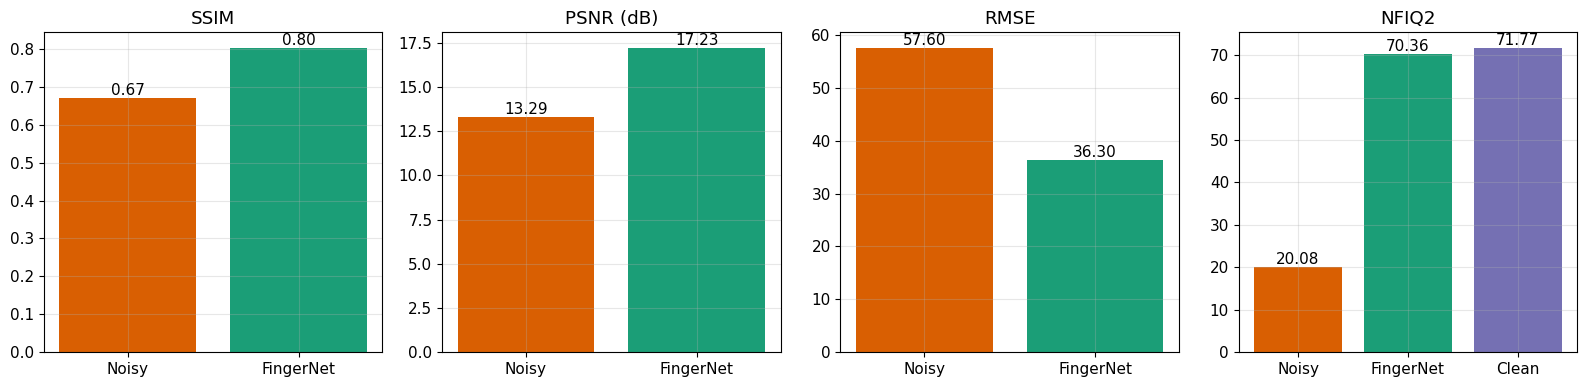

In [35]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, m, t in zip(ax, ["ssim", "psnr", "rmse", "nfiq2"], ["SSIM", "PSNR (dB)", "RMSE", "NFIQ2"]):
    vals = [res[f"{m}_noisy"].mean(), res[f"{m}_enh"].mean()]
    labels = ["Noisy", "FingerNet"]; cols = [C_NOISY, C_ENH]
    if m == "nfiq2":
        vals.append(res.nfiq2_clean.mean()); labels.append("Clean"); cols.append(C_CLEAN)
    b = a.bar(labels, vals, color=cols)
    a.bar_label(b, fmt="%.2f"); a.set_title(t)
save("g2_before_after")

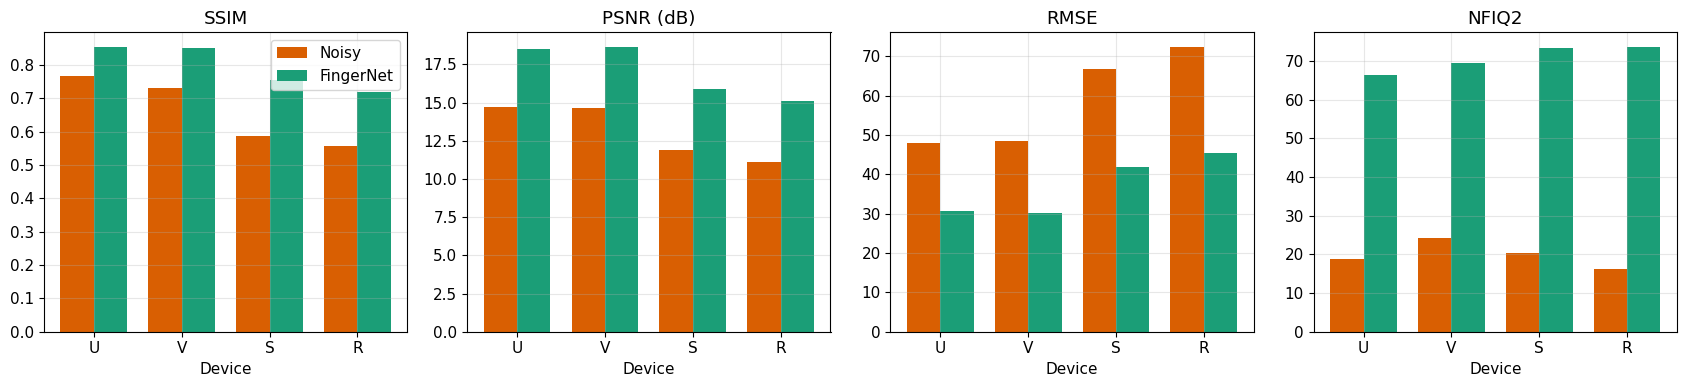

In [36]:
g = res.groupby("device").mean(numeric_only=True).loc[["U", "V", "S", "R"]]
fig, ax = plt.subplots(1, 4, figsize=(17, 4)); x = np.arange(len(g)); w = 0.38
for a, m, t in zip(ax, ["ssim", "psnr", "rmse", "nfiq2"], ["SSIM", "PSNR (dB)", "RMSE", "NFIQ2"]):
    a.bar(x - w/2, g[f"{m}_noisy"], w, label="Noisy", color=C_NOISY)
    a.bar(x + w/2, g[f"{m}_enh"], w, label="FingerNet", color=C_ENH)
    a.set_xticks(x); a.set_xticklabels(g.index); a.set_title(t); a.set_xlabel("Device")
ax[0].legend(); save("g3_per_device")

/tmp/ipykernel_49/37867945.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot([res.nfiq2_noisy, res.nfiq2_enh, res.nfiq2_clean],


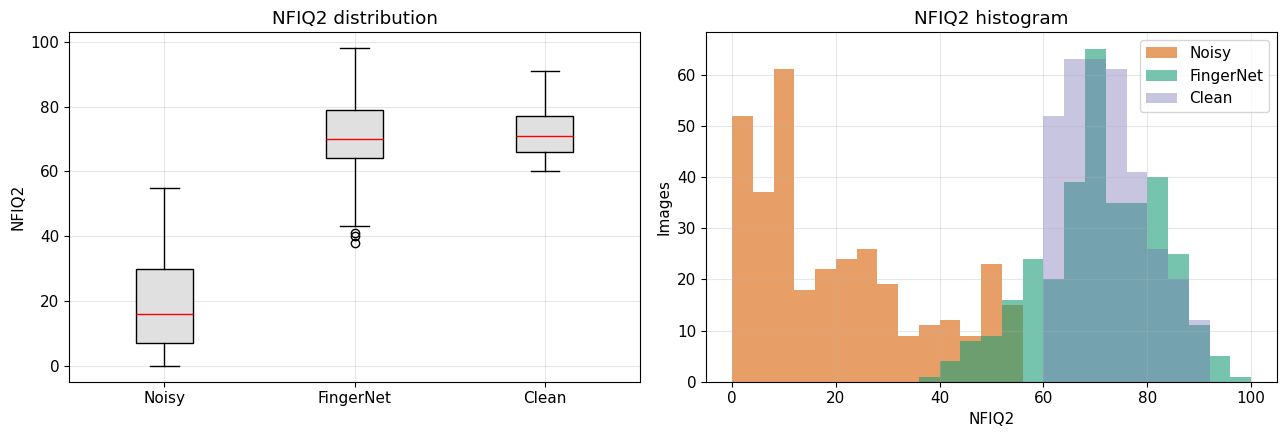

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].boxplot([res.nfiq2_noisy, res.nfiq2_enh, res.nfiq2_clean],
              labels=["Noisy", "FingerNet", "Clean"], patch_artist=True,
              boxprops=dict(facecolor="#e0e0e0"), medianprops=dict(color="red"))
ax[0].set_ylabel("NFIQ2"); ax[0].set_title("NFIQ2 distribution")
bins = np.linspace(0, 100, 26)
ax[1].hist(res.nfiq2_noisy, bins, alpha=0.6, label="Noisy", color=C_NOISY)
ax[1].hist(res.nfiq2_enh, bins, alpha=0.6, label="FingerNet", color=C_ENH)
ax[1].hist(res.nfiq2_clean, bins, alpha=0.4, label="Clean", color=C_CLEAN)
ax[1].set_xlabel("NFIQ2"); ax[1].set_ylabel("Images"); ax[1].legend(); ax[1].set_title("NFIQ2 histogram")
save("g4_nfiq2_distribution")

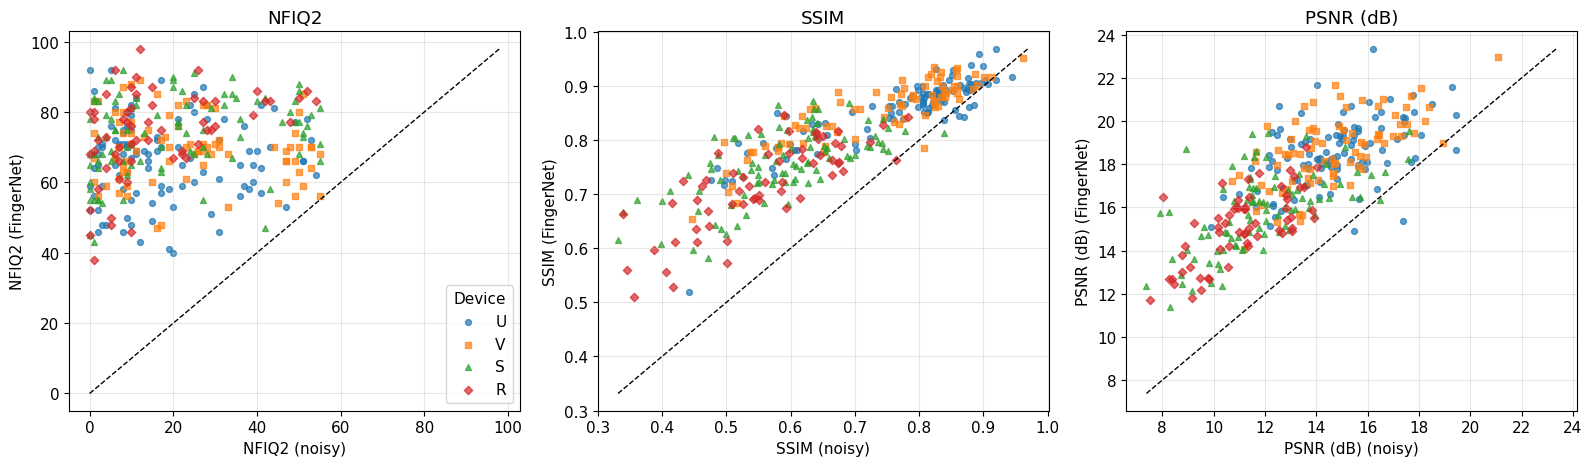

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, m, t in zip(ax, ["nfiq2", "ssim", "psnr"], ["NFIQ2", "SSIM", "PSNR (dB)"]):
    lo = min(res[f"{m}_noisy"].min(), res[f"{m}_enh"].min()); hi = max(res[f"{m}_noisy"].max(), res[f"{m}_enh"].max())
    for d, mk in zip(["U", "V", "S", "R"], ["o", "s", "^", "D"]):
        s = res[res.device == d]
        a.scatter(s[f"{m}_noisy"], s[f"{m}_enh"], s=18, alpha=0.7, marker=mk, label=d)
    a.plot([lo, hi], [lo, hi], "k--", lw=1)   # y = x: is line ke upar = improvement
    a.set_xlabel(f"{t} (noisy)"); a.set_ylabel(f"{t} (FingerNet)"); a.set_title(t)
ax[0].legend(title="Device"); save("g5_scatter")

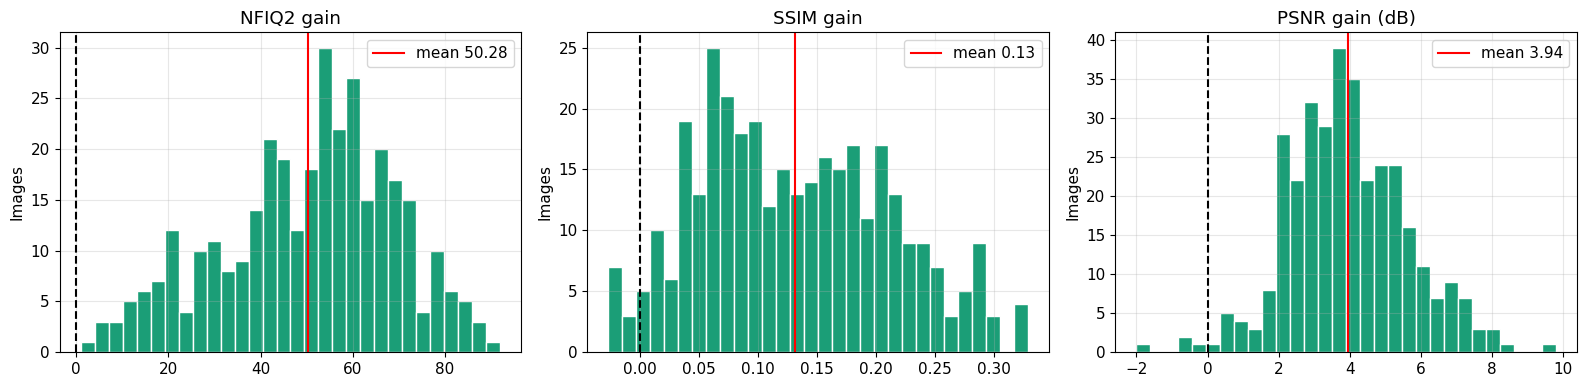

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, m, t in zip(ax, ["nfiq2", "ssim", "psnr"], ["NFIQ2 gain", "SSIM gain", "PSNR gain (dB)"]):
    d = res[f"{m}_enh"] - res[f"{m}_noisy"]
    a.hist(d, bins=30, color=C_ENH, edgecolor="white")
    a.axvline(0, c="k", ls="--"); a.axvline(d.mean(), c="red", label=f"mean {d.mean():.2f}")
    a.set_title(t); a.set_ylabel("Images"); a.legend()
save("g6_improvement_hist")

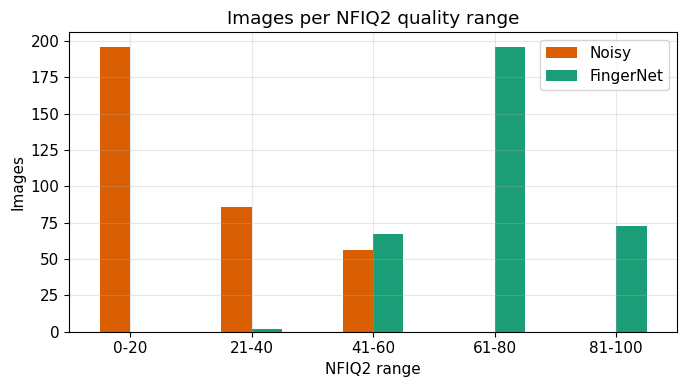

In [40]:
bins_ = [0, 20, 40, 60, 80, 100]; lab = ["0-20", "21-40", "41-60", "61-80", "81-100"]
res["bin_noisy"] = pd.cut(res.nfiq2_noisy, bins_, labels=lab, include_lowest=True)
res["bin_enh"] = pd.cut(res.nfiq2_enh, bins_, labels=lab, include_lowest=True)
ct = pd.concat([res.bin_noisy.value_counts().sort_index().rename("Noisy"),
                res.bin_enh.value_counts().sort_index().rename("FingerNet")], axis=1)
ct.plot(kind="bar", color=[C_NOISY, C_ENH], figsize=(7, 4), rot=0)
plt.xlabel("NFIQ2 range"); plt.ylabel("Images"); plt.title("Images per NFIQ2 quality range")
save("g7_nfiq2_bins")

In [41]:
import shutil
from IPython.display import FileLink

shutil.make_archive("/kaggle/working/fingernet_out", "zip", "/kaggle/working", "fingernet_out")
print("Size: %.1f MB" % (os.path.getsize("/kaggle/working/fingernet_out.zip") / 1e6))
FileLink("fingernet_out.zip")

Size: 71.5 MB


/kaggle/working/fingernet_out.zip